## FOOD ORDERS Analysis_ELT

## 1. Import libraries

Pandas helps us read and analyse data.  
Matplotlib helps us draw charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## 2. Load the dataset

`raw_df` keeps the original data safe.  
`work_df` is the copy that we clean.

In [2]:
raw_df = pd.read_csv("food_orders.csv")
work_df = raw_df.copy()

print(raw_df.shape)
display(raw_df.head())

(1010, 14)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,NaN,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


## 3. Understand the data

These commands show sample rows, column names and data types.  
The summary gives a quick view of the dataset.

In [3]:
display(raw_df.head())
display(raw_df.tail())
display(raw_df.sample(5))
print(raw_df.columns)
raw_df.info()
display(raw_df.describe(include="all"))

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,NaN,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
356,357,C1635,R2758,2024-01-26 01:26:00,2024-01-26 03:18:00,1394.0,40.0,Cash on Delivery,15% New User,111.0,31.0,0.0,Rainy,Mobile App
429,430,C9306,R2583,2024-01-02 08:53:33,2024-01-02 10:34:33,521.0,NaN,Digital Wallet,5% on App,173.0,39.0,0.0,Rainy,Mobile App
33,34,C2528,R2578,2024-01-23 11:40:11,2024-01-23 12:17:11,NaN,40.0,Credit Card,NaN,67.0,25.0,0.0,Sunny,Partner App
540,541,C8576,R2215,2024-01-23 20:39:14,2024-01-23 22:27:14,1966.0,0.0,Cash on Delivery,15% New User,109.0,12.0,0.0,Humid,Website
602,603,C9415,R2466,2024-01-29 22:43:22,2024-01-30 00:12:22,1270.0,20.0,Credit Card,15% New User,197.0,21.0,0.0,Humid,Mobile App


Index(['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time',
       'Delivery Date and Time', 'Order Value', 'Delivery Fee',
       'Payment Method', 'Discounts and Offers', 'Commission Fee',
       'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition',
       'Order Channel'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1010 non-null   int64  
 1   Customer ID             1010 non-null   str    
 2   Restaurant ID           1010 non-null   str    
 3   Order Date and Time     1010 non-null   str    
 4   Delivery Date and Time  1010 non-null   str    
 5   Order Value             969 non-null    float64
 6   Delivery Fee            960 non-null    float64
 7   Payment Method          960 non-null    str    
 8   Discounts and Offers    768 non-null    str

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
count,1010.000000,1010,1010,1010,1010,969.000000,960.000000,960,768,970.000000,959.000000,970.000000,1010,1010
unique,NaN,947,621,1000,1000,NaN,NaN,3,4,NaN,NaN,NaN,4,3
top,NaN,C7949,R2317,2024-02-05 05:55:15,2024-02-05 07:33:15,NaN,NaN,Cash on Delivery,10%,NaN,NaN,NaN,Sunny,Mobile App
freq,NaN,3,6,2,2,NaN,NaN,341,221,NaN,NaN,NaN,405,693
mean,499.221782,NaN,NaN,NaN,NaN,1055.901961,28.625000,NaN,NaN,127.042268,29.895725,27.886598,NaN,NaN
std,288.589479,NaN,NaN,NaN,NaN,529.534182,16.927281,NaN,NaN,43.013345,11.731583,49.383898,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,104.000000,0.000000,NaN,NaN,50.000000,10.000000,0.000000,NaN,NaN
25%,248.250000,NaN,NaN,NaN,NaN,600.000000,20.000000,NaN,NaN,90.250000,20.000000,0.000000,NaN,NaN
50%,498.500000,NaN,NaN,NaN,NaN,1041.000000,30.000000,NaN,NaN,128.000000,30.000000,0.000000,NaN,NaN
75%,748.750000,NaN,NaN,NaN,NaN,1494.000000,40.000000,NaN,NaN,164.000000,40.000000,50.000000,NaN,NaN


**Observation:** One row represents one food order.  
Order value, delivery time, payment method, fees, refunds and order channel help analyse business performance.

## 4. Check missing values and duplicates

This section counts empty cells and duplicate rows.  
We also check whether Order IDs are repeated.

In [4]:
display(raw_df.isnull().sum())
print("Duplicate rows:", raw_df.duplicated().sum())
print("Repeated Order IDs:", raw_df["Order ID"].duplicated().sum())

Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                41
Delivery Fee               50
Payment Method             50
Discounts and Offers      242
Commission Fee             40
Payment Processing Fee     51
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
dtype: int64

Duplicate rows: 10
Repeated Order IDs: 10


## 5. Check dates and financial values

We convert date columns temporarily to check invalid dates.  
We also check for negative amounts and impossible delivery times.

In [5]:
order_date = pd.to_datetime(raw_df["Order Date and Time"], errors="coerce")
delivery_date = pd.to_datetime(raw_df["Delivery Date and Time"], errors="coerce")

delivery_minutes = (delivery_date - order_date).dt.total_seconds() / 60

print("Invalid order dates:", order_date.isnull().sum())
print("Invalid delivery dates:", delivery_date.isnull().sum())
print("Negative delivery times:", (delivery_minutes < 0).sum())
print("Over 24 hour deliveries:", (delivery_minutes > 1440).sum())

Invalid order dates: 0
Invalid delivery dates: 0
Negative delivery times: 0
Over 24 hour deliveries: 0


In [6]:
money_columns = ["Order Value", "Delivery Fee", "Commission Fee",
                 "Payment Processing Fee", "Refunds/Chargebacks"]

money_check = raw_df[money_columns].apply(pd.to_numeric, errors="coerce")
display((money_check < 0).sum())

Order Value               0
Delivery Fee              0
Commission Fee            0
Payment Processing Fee    0
Refunds/Chargebacks       0
dtype: int64

## 6. Check category values

Value counts show how many orders belong to each category.  
Missing category values are also displayed.

In [7]:
print(raw_df["Payment Method"].value_counts(dropna=False))
print(raw_df["Discounts and Offers"].value_counts(dropna=False))
print(raw_df["Weather Condition"].value_counts(dropna=False))
print(raw_df["Order Channel"].value_counts(dropna=False))

Payment Method
Cash on Delivery    341
Credit Card         323
Digital Wallet      296
NaN                  50
Name: count, dtype: int64
Discounts and Offers
NaN             242
10%             221
50 off Promo    194
15% New User    183
5% on App       170
Name: count, dtype: int64
Weather Condition
Sunny     405
Cloudy    252
Rainy     202
Humid     151
Name: count, dtype: int64
Order Channel
Mobile App     693
Partner App    165
Website        152
Name: count, dtype: int64


## 7. Cleaning rules

We remove exact duplicate rows and keep the first row for a repeated Order ID.  
Missing financial values stay empty; missing category values are labelled clearly.

| Problem | Simple rule | Reason |
|---|---|---|
| Duplicate rows | Remove exact duplicates | Avoid duplicate counting |
| Repeated Order ID | Keep first row; save others for checking | One ID should represent one order |
| Missing Order Value | Keep empty | Do not guess money values |
| Missing fees/refunds | Keep empty | Missing is not zero |
| Missing payment | Use `Unknown` | Payment is not known |
| Missing offer | Use `Not Specified` | Offer details are not known |
| Invalid dates | Keep as missing after conversion | Cannot calculate delivery time |
| Negative delivery time | Flag as invalid | Delivery cannot be before order |

## 8. Clean the data

We clean only `work_df`, not the original data.  
Repeated Order ID rows are saved separately for checking.

In [8]:
original_rows = len(raw_df)

work_df = raw_df.copy()
work_df = work_df.drop_duplicates()

repeated_rows = work_df[work_df["Order ID"].duplicated()]
work_df = work_df.drop_duplicates(subset="Order ID")

for col in money_columns:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

work_df["Order Date and Time"] = pd.to_datetime(
    work_df["Order Date and Time"], errors="coerce")
work_df["Delivery Date and Time"] = pd.to_datetime(
    work_df["Delivery Date and Time"], errors="coerce")

work_df["Payment Method"] = work_df["Payment Method"].fillna("Unknown")
work_df["Discounts and Offers"] = work_df["Discounts and Offers"].fillna("Not Specified")

print("Original rows:", original_rows)
print("Cleaned rows:", len(work_df))
print("Repeated rows removed:", len(repeated_rows))
display(work_df.head())

Original rows: 1010
Cleaned rows: 1000
Repeated rows removed: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


## 9. Create new columns

Delivery time is the difference between delivery and order timestamps.  
Platform revenue is calculated only when all four financial values are present.

In [9]:
work_df["Delivery_Time_Minutes"] = (
    work_df["Delivery Date and Time"] - work_df["Order Date and Time"]
).dt.total_seconds() / 60

work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour

work_df["Platform_Net_Revenue"] = (
    work_df["Commission Fee"] + work_df["Delivery Fee"]
    - work_df["Payment Processing Fee"] - work_df["Refunds/Chargebacks"]
)

work_df.loc[
    work_df[money_columns[1:]].isnull().any(axis=1),
    "Platform_Net_Revenue"
] = None

work_df["Valid_Delivery"] = (
    (work_df["Delivery_Time_Minutes"] >= 0) &
    (work_df["Delivery_Time_Minutes"] <= 1440)
)

display(work_df.head())

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue,Valid_Delivery
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App,88.0,2024-02-01,1,103.0,True
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App,35.0,2024-02-02,22,215.0,True
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App,58.0,2024-01-31,5,180.0,True
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App,46.0,2024-01-16,22,NaN,True
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App,89.0,2024-01-29,1,NaN,True


## 10.Business questions

Missing order values are not included in order-value calculations.  
Only valid delivery times and complete revenue values are used.

In [10]:
orders = work_df["Order Value"].dropna()
delivery = work_df.loc[work_df["Valid_Delivery"], "Delivery_Time_Minutes"]
revenue = work_df["Platform_Net_Revenue"].dropna()

print("Original records:", original_rows)
print("Cleaned records:", len(work_df))
print("Valid order values:", len(orders))
print("Total order value:", orders.sum())
print("Average order value:", orders.mean())
print("Median order value:", orders.median())

Original records: 1010
Cleaned records: 1000
Valid order values: 960
Total order value: 1013415.0
Average order value: 1055.640625
Median order value: 1040.0


In [11]:
print("Payment method with most orders:")
display(work_df[work_df["Payment Method"] != "Unknown"]
        ["Payment Method"].value_counts().head(1))

print("Order channel with most orders:")
display(work_df["Order Channel"].value_counts().head(1))

print("Most common weather:")
display(work_df["Weather Condition"].value_counts().head(1))

Payment method with most orders:


Payment Method
Cash on Delivery    336
Name: count, dtype: int64

Order channel with most orders:


Order Channel
Mobile App    686
Name: count, dtype: int64

Most common weather:


Weather Condition
Sunny    402
Name: count, dtype: int64

In [12]:
print("Average delivery time:", delivery.mean())
print("Median delivery time:", delivery.median())

print("Top five restaurants:")
display(work_df["Restaurant ID"].value_counts().head(5))

print("Total platform net revenue:", revenue.sum())
print("Revenue records used:", len(revenue))

Average delivery time: 73.575
Median delivery time: 74.0
Top five restaurants:


Restaurant ID
R2317    6
R2804    5
R2726    5
R2016    5
R2523    5
Name: count, dtype: int64

Total platform net revenue: 80877.0
Revenue records used: 828


## 11. Draw charts

The first chart shows order counts for each channel.  
The second chart compares average delivery times by weather condition.

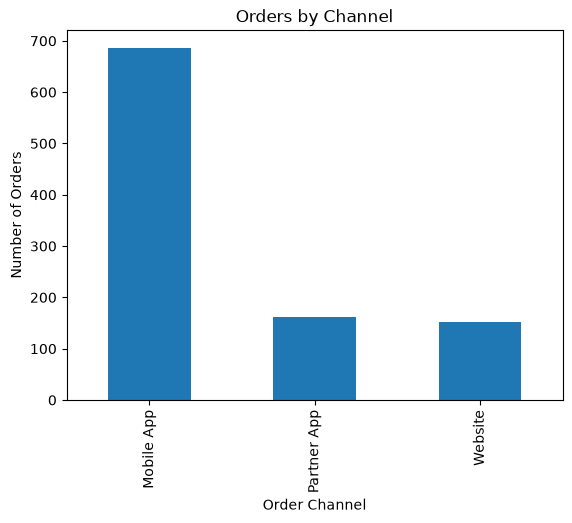

In [13]:
work_df["Order Channel"].value_counts().plot(kind="bar")
plt.title("Orders by Channel")
plt.xlabel("Order Channel")
plt.ylabel("Number of Orders")
plt.show()

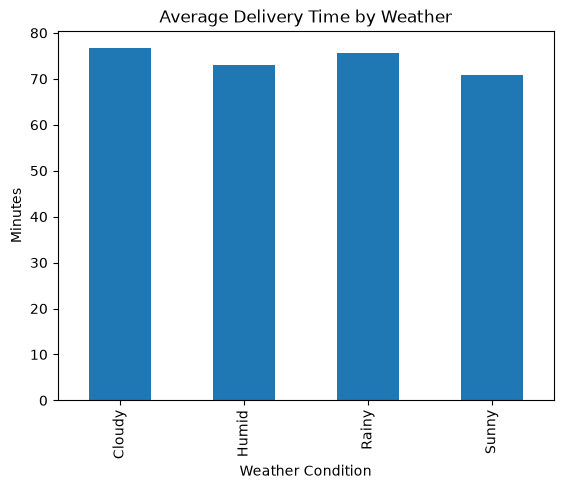

In [14]:
work_df[work_df["Valid_Delivery"]].groupby(
    "Weather Condition"
)["Delivery_Time_Minutes"].mean().plot(kind="bar")

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Minutes")
plt.show()

## 12. Validate the data

These checks show whether duplicates and negative delivery times remain.  
We also compare missing values before and after cleaning.

In [14]:
print("Duplicate rows left:", work_df.duplicated().sum())
print("Repeated Order IDs left:", work_df["Order ID"].duplicated().sum())
print("Negative delivery times:",
      (work_df["Delivery_Time_Minutes"] < 0).sum())

print("Missing values before cleaning:")
display(raw_df.isnull().sum())

print("Missing values after cleaning:")
display(work_df.isnull().sum())

Duplicate rows left: 0
Repeated Order IDs left: 0
Negative delivery times: 0
Missing values before cleaning:


Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                41
Delivery Fee               50
Payment Method             50
Discounts and Offers      242
Commission Fee             40
Payment Processing Fee     51
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
dtype: int64

Missing values after cleaning:


Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                40
Delivery Fee               50
Payment Method              0
Discounts and Offers        0
Commission Fee             40
Payment Processing Fee     50
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
Delivery_Time_Minutes       0
Order_Date                  0
Order_Hour                  0
Platform_Net_Revenue      172
Valid_Delivery              0
dtype: int64

## 13. Save cleaned data and validation report

The cleaned data is saved as a CSV file.  
The report records important row counts for submission.

In [15]:
work_df.to_csv("food_orders_cleaned.csv", index=False)

report = pd.DataFrame({
    "Item": ["Original rows", "Cleaned rows", "Repeated Order ID rows removed",
             "Missing Order Value", "Invalid delivery times",
             "Revenue records used"],
    "Count": [original_rows, len(work_df), len(repeated_rows),
              work_df["Order Value"].isnull().sum(),
              (~work_df["Valid_Delivery"]).sum(), len(revenue)]
})

display(report)
report.to_csv("food_orders_validation_report.csv", index=False)

,Item,Count
0,Original rows,1010
1,Cleaned rows,1000
2,Repeated Order ID rows removed,0
3,Missing Order Value,40
4,Invalid delivery times,0
5,Revenue records used,828


# Part B — MySQL Batch Pipeline

The following shows how to load source data into MySQL in groups of 100 rows.  


## 14. Connect to MySQL

Install the connector if it is not already installed.  
Enter your own MySQL password in the configuration.

In [ ]:
# Install once if needed:
%pip install mysql-connector-python

import mysql.connector

connection_info = {
    "host": "localhost",
    "user": "root",
    "password": "YOUR OWN PASSWORD"
}

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 15. Create the raw database and table

The raw database stores the original CSV rows.  
All source columns are stored as text to keep the original values.

In [17]:
connection = mysql.connector.connect(**connection_info)
cursor = connection.cursor()

cursor.execute("CREATE DATABASE IF NOT EXISTS food_orders_raw_db")
cursor.execute("USE food_orders_raw_db")

columns = ", ".join(["`" + col + "` TEXT" for col in raw_df.columns])
cursor.execute("CREATE TABLE IF NOT EXISTS raw_food_orders (" + columns + ")")

connection.commit()
cursor.close()
connection.close()

## 16. Load CSV rows in batches

`chunksize=100` reads 100 records at a time.  
`executemany()` inserts the complete batch and `commit()` saves it.

In [18]:
connection = mysql.connector.connect(
    **connection_info, database="food_orders_raw_db")
cursor = connection.cursor()

columns = ", ".join(["`" + col + "`" for col in raw_df.columns])
marks = ", ".join(["%s"] * len(raw_df.columns))
query = "INSERT INTO raw_food_orders (" + columns + ") VALUES (" + marks + ")"

total = 0
for number, batch in enumerate(
    pd.read_csv("food_orders.csv", chunksize=100, dtype=str), start=1
):
    rows = [tuple(None if pd.isna(value) else value for value in row)
            for row in batch.itertuples(index=False, name=None)]
    cursor.executemany(query, rows)
    connection.commit()
    total = total + len(rows)
    print("Batch", number, "loaded:", len(rows))

print("Total loaded:", total)
cursor.close()
connection.close()

Batch 1 loaded: 100
Batch 2 loaded: 100
Batch 3 loaded: 100
Batch 4 loaded: 100
Batch 5 loaded: 100
Batch 6 loaded: 100
Batch 7 loaded: 100
Batch 8 loaded: 100
Batch 9 loaded: 100
Batch 10 loaded: 100
Batch 11 loaded: 10
Total loaded: 1010


## 17. Retrieve raw records in batches

We read the raw table 100 records at a time.  
The raw table is not changed by this step.

In [19]:
connection = mysql.connector.connect(
    **connection_info, database="food_orders_raw_db")

start = 0
while True:
    query = "SELECT * FROM raw_food_orders LIMIT 100 OFFSET " + str(start)
    batch = pd.read_sql(query, connection)

    if len(batch) == 0:
        break

    print("Retrieved records:", len(batch))
    display(batch.head(2))
    start = start + 100

connection.close()

Retrieved records: 100


C:\Users\CH.UVS SIMHADRI BABU\AppData\Local\Temp\ipykernel_23120\1413815673.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  batch = pd.read_sql(query, connection)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App


Retrieved records: 100


C:\Users\CH.UVS SIMHADRI BABU\AppData\Local\Temp\ipykernel_23120\1413815673.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  batch = pd.read_sql(query, connection)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,101,C6056,R2592,2024-01-10 06:15:01,2024-01-10 06:46:01,1696.0,NaN,Credit Card,5% on App,128.0,17.0,0.0,Humid,Mobile App
1,102,C9110,R2713,2024-01-23 16:16:46,2024-01-23 17:52:46,1664.0,30.0,Cash on Delivery,NaN,129.0,43.0,0.0,Rainy,Mobile App


... (54 outputs left out)

Retrieved records: 20


C:\Users\CH.UVS SIMHADRI BABU\AppData\Local\Temp\ipykernel_23120\1413815673.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  batch = pd.read_sql(query, connection)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,991,C3065,R2013,2024-01-26 21:40:57,2024-01-26 23:25:57,1575.0,50.0,Cash on Delivery,5% on App,104.0,21.0,0.0,Cloudy,Mobile App
1,992,C1768,R2503,2024-01-04 03:00:40,2024-01-04 04:23:40,948.0,40.0,Digital Wallet,10%,110.0,18.0,0.0,Rainy,Mobile App


C:\Users\CH.UVS SIMHADRI BABU\AppData\Local\Temp\ipykernel_23120\1413815673.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  batch = pd.read_sql(query, connection)


## 18. Transform and validate one batch

The function converts date and money columns and calculates delivery time.  
Rows with invalid delivery times are separated from valid rows.

In [20]:
def clean_batch(batch):
    batch = batch.drop_duplicates().copy()

    batch["Order Date and Time"] = pd.to_datetime(
        batch["Order Date and Time"], errors="coerce")
    batch["Delivery Date and Time"] = pd.to_datetime(
        batch["Delivery Date and Time"], errors="coerce")

    for col in money_columns:
        batch[col] = pd.to_numeric(batch[col], errors="coerce")

    batch["Delivery_Time_Minutes"] = (
        batch["Delivery Date and Time"] - batch["Order Date and Time"]
    ).dt.total_seconds() / 60

    batch["Platform_Net_Revenue"] = (
        batch["Commission Fee"] + batch["Delivery Fee"]
        - batch["Payment Processing Fee"] - batch["Refunds/Chargebacks"]
    )

    return batch

example_batch = clean_batch(raw_df.head(100))

valid_batch = example_batch[
    example_batch["Delivery_Time_Minutes"].between(0, 1440)
]
rejected_batch = example_batch.drop(valid_batch.index)

print("Valid records:", len(valid_batch))
print("Rejected records:", len(rejected_batch))

Valid records: 100
Rejected records: 0


## 19. Create the analytics database

The analytics database is separate from the raw database.  


In [21]:
connection = mysql.connector.connect(**connection_info)
cursor = connection.cursor()

cursor.execute("CREATE DATABASE IF NOT EXISTS food_orders_analytics_db")
connection.commit()

cursor.close()
connection.close()

## 20. Load transformed records

The table stores transformed rows as JSON.  
The insert uses a batch operation and commits the rows to MySQL.

In [22]:
import json
import pandas as pd

connection = mysql.connector.connect(
    **connection_info,
    database="food_orders_analytics_db"
)

cursor = connection.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS cleaned_food_orders (
    id INT AUTO_INCREMENT PRIMARY KEY,
    order_data JSON
)
""")

batch_size = 10

for start in range(0, len(valid_batch), batch_size):

    small_batch = valid_batch.iloc[start:start + batch_size]

    rows = []

    for row in small_batch.to_dict(orient="records"):
        clean_row = {
            key: (None if pd.isna(value) else value)
            for key, value in row.items()
        }

        rows.append((
            json.dumps(clean_row, default=str, allow_nan=False),
        ))

    cursor.executemany(
        "INSERT INTO cleaned_food_orders (order_data) VALUES (%s)",
        rows
    )

    connection.commit()

    print("Inserted:", start + len(rows))

print("All records inserted successfully!")

cursor.close()
connection.close()

Inserted: 10
Inserted: 20
Inserted: 30
Inserted: 40
Inserted: 50
Inserted: 60
Inserted: 70
Inserted: 80
Inserted: 90
Inserted: 100
All records inserted successfully!


## 21. SQL business questions

These SQL statements show how to calculate the requested business metrics.  

In [23]:
sql = [
    "SELECT SUM(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Value')) AS DECIMAL(10,2))) FROM cleaned_food_orders",
    "SELECT AVG(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Value')) AS DECIMAL(10,2))) FROM cleaned_food_orders",
    "SELECT JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Payment Method')), COUNT(*) FROM cleaned_food_orders GROUP BY 1 ORDER BY 2 DESC LIMIT 1",
    "SELECT JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Channel')), COUNT(*) FROM cleaned_food_orders GROUP BY 1 ORDER BY 2 DESC LIMIT 1",
    "SELECT AVG(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Delivery_Time_Minutes')) AS DECIMAL(10,2))) FROM cleaned_food_orders",
    "SELECT SUM(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Platform_Net_Revenue')) AS DECIMAL(10,2))) FROM cleaned_food_orders"
]

for query in sql:
    print(query)

SELECT SUM(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Value')) AS DECIMAL(10,2))) FROM cleaned_food_orders
SELECT AVG(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Value')) AS DECIMAL(10,2))) FROM cleaned_food_orders
SELECT JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Payment Method')), COUNT(*) FROM cleaned_food_orders GROUP BY 1 ORDER BY 2 DESC LIMIT 1
SELECT JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Order Channel')), COUNT(*) FROM cleaned_food_orders GROUP BY 1 ORDER BY 2 DESC LIMIT 1
SELECT AVG(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Delivery_Time_Minutes')) AS DECIMAL(10,2))) FROM cleaned_food_orders
SELECT SUM(CAST(JSON_UNQUOTE(JSON_EXTRACT(order_data, '$.Platform_Net_Revenue')) AS DECIMAL(10,2))) FROM cleaned_food_orders


## 22. Final report

This summary shows the main counts from the Pandas analysis.  
Check the MySQL table counts after running the database steps.

In [24]:
print("Records in source CSV:", len(raw_df))
print("Records after cleaning:", len(work_df))
print("Rejected delivery records:", len(work_df) - work_df["Valid_Delivery"].sum())
print("Records with revenue:", work_df["Platform_Net_Revenue"].notna().sum())
print("Saved: food_orders_cleaned.csv")
print("Saved: food_orders_validation_report.csv")

Records in source CSV: 1010
Records after cleaning: 1000
Rejected delivery records: 0
Records with revenue: 828
Saved: food_orders_cleaned.csv
Saved: food_orders_validation_report.csv


## Conclusion

The notebook contains Pandas to inspect, clean, transform and analyse food-order records.  
The MySQL examples demonstrate batch loading from a raw database into a separate analytics database.